# Part 5: Deep Learning

Covers Neural Networks from One Neuron Up through Reference. The [README](README.md) has the same content with the full table of contents; datasets and versions are listed in its Setup section.

In [1]:
# Shared setup: imports and paths used throughout. Run this cell first.
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")      # keep TensorFlow's start-up logs quiet
from pathlib import Path
import logging, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="(Degrees of freedom|divide by zero|invalid value)")  # sparse correlations
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)  # Prophet's backend is chatty
logging.getLogger("tensorflow").setLevel(logging.ERROR)
DATA = Path("data")
IMAGES = Path("images")                                   # animations are written here
MODELS = Path("models")                                   # saved models
IMAGES.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
np.random.seed(42)                                        # for the classic np.random API
rng = np.random.default_rng(42)                           # for new code
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False})

print("pandas", pd.__version__, "| NumPy", np.__version__)

pandas 3.0.5 | NumPy 2.5.3


<a id="17-neural-networks-from-one-neuron-up"></a>

## 17. Neural Networks from One Neuron Up

The deep learning projects start here. Before calling Keras, it's worth building the pieces by hand once, because
everything later (CNNs and pretrained networks included) is made of the same parts: weighted sums, activations, a loss,
and gradient descent.

<a id="a-single-artificial-neuron"></a>

### A Single Artificial Neuron

A biological neuron collects signals through its dendrites, combines them, and fires a signal down its axon if the
combined input is strong enough. An artificial neuron imitates that with arithmetic:

1. multiply each input $x_i$ by a weight $w_i$ (how much that input matters),
2. add them up and add a bias $b$ (which shifts the result up or down),
3. pass the sum through an **activation function** $f$.

$$y = f\left(\sum_i w_i x_i + b\right)$$

With three inputs, the neuron has four adjustable parameters: three weights and a bias. Training a network means finding
good values for all such parameters.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

x = np.array([0.7, 0.1, 0.3])      # three inputs
w = np.array([0.6, -0.4, 0.9])     # one weight per input
b = 0.1                            # bias

z = w @ x + b                      # weighted sum: 0.6*0.7 - 0.4*0.1 + 0.9*0.3 + 0.1
print(f"weighted sum z = {z:.2f}")
print(f"output sigmoid(z) = {sigmoid(z):.3f}")

weighted sum z = 0.75
output sigmoid(z) = 0.679


<a id="activation-functions"></a>

### Activation Functions

Without an activation, stacking neurons would only ever produce a linear function, because a sum of weighted sums is
still a weighted sum. The activation adds the non-linearity that lets networks model curves.

- **Step**: outputs 0 or 1. The original perceptron; not used for training because its slope is zero everywhere.
- **Sigmoid**: squashes any number into (0, 1). Good for a probability output; slow to train in hidden layers.
- **ReLU** (rectified linear unit): `max(0, z)`. The default for hidden layers: cheap and doesn't saturate for positive
  inputs.
- **Linear** (identity): used in the output layer for regression, so the network can predict any value.
- **Softmax**: turns a vector of scores into probabilities that sum to 1. The output layer for multi-class problems.

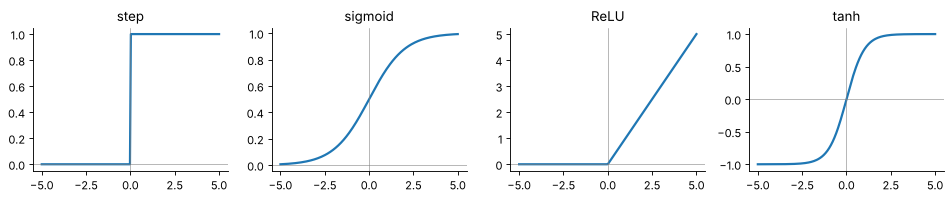

In [3]:
z = np.linspace(-5, 5, 200)
activations = {"step": (z > 0).astype(float), "sigmoid": sigmoid(z),
               "ReLU": np.maximum(0, z), "tanh": np.tanh(z)}

fig, axes = plt.subplots(1, 4, figsize=(12, 2.6), sharex=True)
for ax, (name, y) in zip(axes, activations.items()):
    ax.plot(z, y, lw=2)
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_title(name)
plt.tight_layout(); plt.show()

<a id="layers-are-matrix-multiplications"></a>

### Layers Are Matrix Multiplications

Put two neurons side by side, each seeing the same three inputs, and the six weights fit neatly into a 2×3 matrix. A
whole layer then becomes one matrix product plus a bias vector, followed by the activation:

$$\mathbf{a} = f(W\mathbf{p} + \mathbf{b})$$

Stack layers and you get a **multi-layer perceptron**, also called a fully connected feed-forward network: every neuron
in one layer connects to every neuron in the next, and information flows only forwards.

```mermaid
flowchart LR
    subgraph Input
        x1((x1)); x2((x2)); x3((x3))
    end
    subgraph Hidden["Hidden layer (ReLU)"]
        h1((h1)); h2((h2)); h3((h3)); h4((h4))
    end
    subgraph Output["Output (linear)"]
        y((y))
    end
    x1 --> h1 & h2 & h3 & h4
    x2 --> h1 & h2 & h3 & h4
    x3 --> h1 & h2 & h3 & h4
    h1 & h2 & h3 & h4 --> y
```

The network above has 3×4 + 4 = 16 parameters in the hidden layer and 4×1 + 1 = 5 in the output layer. Keras reports
exactly these counts in `model.summary()`.

In [4]:
p = np.array([0.7, 0.1, 0.3])                 # inputs
W = np.array([[0.6, -0.4, 0.9],               # row 1: weights into neuron 1
              [0.2,  0.8, -0.5]])             # row 2: weights into neuron 2
b = np.array([0.1, -0.2])

a = np.maximum(0, W @ p + b)                  # ReLU(Wp + b): the whole layer in one line
print("layer output:", a.round(3))
print("trainable parameters:", W.size + b.size)

layer output: [0.75 0.  ]
trainable parameters: 8


<a id="how-a-network-learns-loss-gradient-descent-and-backpropagation"></a>

### How a Network Learns: Loss, Gradient Descent and Backpropagation

A freshly created network has random weights, so its predictions are garbage. Training repeats four steps:

1. **Forward pass**: push the inputs through the network to get predictions.
2. **Loss**: measure how wrong they are, for example the mean squared error between prediction and truth.
3. **Backward pass (backpropagation)**: use the chain rule to work out, for every weight, how much the loss would change
   if that weight changed a little. This is the **gradient**.
4. **Update**: nudge every weight a small step against its gradient. The step size is the **learning rate**.

```mermaid
flowchart LR
    A[Inputs] --> B[Forward pass]
    B --> C[Predictions]
    C --> D[Loss vs. true labels]
    D --> E[Backpropagation:<br/>gradient of loss<br/>for every weight]
    E --> F[Gradient descent:<br/>w = w - lr * gradient]
    F --> B
```

This is the same gradient descent that [fitted a straight line](#rules-written-by-data) in section 1, only with
thousands of parameters instead of two. It's like walking downhill in fog: you can't see the valley, but you can feel which way the ground slopes
under your feet and take a step that way. Too small a learning rate and you crawl; too large and you overshoot the
valley and bounce around.

The code below trains a one-hidden-layer network on a noisy curve with nothing but NumPy, writing out the backward pass
by hand, and records the fit as an animation. Keras does exactly this for us later, in one line.

In [5]:
from matplotlib.animation import FuncAnimation, PillowWriter

# Toy data: a noisy curve
X_toy = np.linspace(-3, 3, 80).reshape(-1, 1)
y_toy = np.sin(X_toy) + 0.15 * rng.standard_normal(X_toy.shape)

# 1 input -> 16 hidden (tanh) -> 1 output (linear)
W1, b1 = rng.normal(0, 1, (1, 16)), np.zeros(16)
W2, b2 = rng.normal(0, 0.3, (16, 1)), np.zeros(1)
lr, snapshots, losses = 0.05, [], []

for epoch in range(3001):
    h = np.tanh(X_toy @ W1 + b1)                 # forward pass
    pred = h @ W2 + b2
    err = pred - y_toy
    losses.append((err ** 2).mean())             # mean squared error
    d_pred = 2 * err / len(X_toy)                # backward pass (chain rule, layer by layer)
    dW2, db2 = h.T @ d_pred, d_pred.sum(0)
    d_h = (d_pred @ W2.T) * (1 - h ** 2)         # derivative of tanh
    dW1, db1 = X_toy.T @ d_h, d_h.sum(0)
    for param, grad in ((W1, dW1), (b1, db1), (W2, dW2), (b2, db2)):
        param -= lr * grad                       # gradient descent step
    if epoch % 75 == 0:
        snapshots.append((epoch, pred.ravel().copy()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
ax1.scatter(X_toy, y_toy, s=10, color="grey")
line, = ax1.plot(X_toy, snapshots[0][1], color="crimson", lw=2)
ax2.plot(losses, color="steelblue"); ax2.set_yscale("log")
dot, = ax2.plot([0], [losses[0]], "o", color="crimson")
ax2.set_xlabel("epoch"); ax2.set_ylabel("MSE (log scale)")

def update(i):
    epoch, p = snapshots[i]
    line.set_ydata(p); dot.set_data([epoch], [losses[epoch]])
    ax1.set_title(f"epoch {epoch}")
    return line, dot

FuncAnimation(fig, update, frames=len(snapshots), interval=120).save(
    IMAGES / "network-learning.gif", writer=PillowWriter(fps=8))
plt.close(fig)
print(f"MSE after training: {losses[-1]:.4f}")

MSE after training: 0.0166


![A small network fitting a curve as gradient descent runs](images/network-learning.gif)

Each frame shows the network's prediction after another 75 epochs of gradient descent. It starts nearly flat, quickly
captures the overall shape, then slowly refines the bends while the loss on the right keeps falling.

A network with enough parameters can memorise its training data, so everything from
[the framework section](#underfitting-overfitting-and-the-goldilocks-zone) applies here too: hold out validation and test
data, and watch for training and validation loss drifting apart. Dropout and data augmentation, two remedies specific to
neural networks, come up in the CNN projects.

#### Exercise 11

Re-run the NumPy network with learning rates of `0.005` and `0.5`. What happens to the final MSE in each case? Keep the
data the same by recreating the weights with a fresh `np.random.default_rng(0)`.

#### Solution 11

*Try it yourself before running this cell.*

In [6]:
def train_toy(lr, epochs=3000):
    g = np.random.default_rng(0)
    W1, b1 = g.normal(0, 1, (1, 16)), np.zeros(16)
    W2, b2 = g.normal(0, 0.3, (16, 1)), np.zeros(1)
    for _ in range(epochs):
        h = np.tanh(X_toy @ W1 + b1); err = h @ W2 + b2 - y_toy
        d = 2 * err / len(X_toy); d_h = (d @ W2.T) * (1 - h ** 2)
        W2 -= lr * h.T @ d; b2 -= lr * d.sum(0); W1 -= lr * X_toy.T @ d_h; b1 -= lr * d_h.sum(0)
    return (err ** 2).mean()

for lr in (0.005, 0.05, 0.5):
    print(f"lr={lr:<6} final MSE={train_toy(lr):.4f}")
# Too small: still underfitting after 3000 steps. Too large: steps overshoot and the loss can stall or blow up.

lr=0.005  final MSE=0.0329


lr=0.05   final MSE=0.0166


lr=0.5    final MSE=nan


<a id="18-project-predicting-car-purchase-amounts"></a>

## 18. Project: Predicting Car Purchase Amounts

A car dealer wants to estimate how much a customer is likely to spend on a car from a few facts about them: gender, age,
annual salary, credit card debt and net worth. The target is a dollar amount, so this is a **regression** problem, and
we'll solve it with a small fully connected network.

<a id="loading-and-exploring-the-customer-data"></a>

### Loading and Exploring the Customer Data

The file has 500 customers. Three columns (name, e-mail, country) identify people rather than describe their finances,
so they're dropped. Country could in principle carry signal, but here it has hundreds of values for 500 rows, which is
far too sparse to learn from.

**Watch out:** the file isn't UTF-8. Reading it without `encoding="ISO-8859-1"` fails on accented names.

In [7]:
car_df = pd.read_csv(DATA / "car-purchasing.csv", encoding="ISO-8859-1")
print(car_df.shape)
print(car_df.drop(columns=["Customer e-mail"]).head(3).to_string())
print("\ncountries:", car_df["Country"].nunique())

(500, 9)
     Customer Name   Country  Gender        Age  Annual Salary  Credit Card Debt    Net Worth  Car Purchase Amount
0    Martina Avila  Bulgaria       0  41.851720    62812.09301      11609.380910  238961.2505          35321.45877
1    Harlan Barnes    Belize       0  40.870623    66646.89292       9572.957136  530973.9078          45115.52566
2  Naomi Rodriquez   Algeria       1  43.152897    53798.55112      11160.355060  638467.1773          42925.70921

countries: 211


Car Purchase Amount    1.00
Age                    0.63
Annual Salary          0.62
Net Worth              0.49
Credit Card Debt       0.03
Gender                -0.07


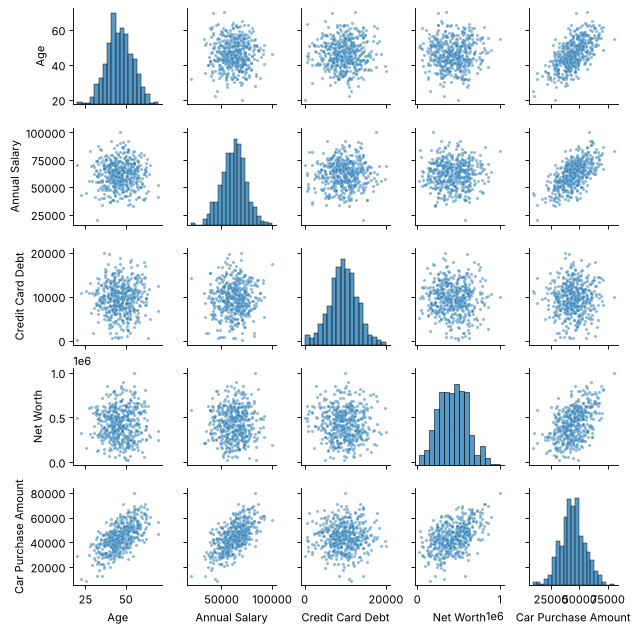

In [8]:
features = ["Gender", "Age", "Annual Salary", "Credit Card Debt", "Net Worth"]
target = "Car Purchase Amount"

print(car_df[features + [target]].corr()[target].round(2).sort_values(ascending=False).to_string())
sns.pairplot(car_df[features[1:] + [target]], height=1.6, plot_kws={"s": 8, "alpha": 0.5})
plt.show()

Age, salary and net worth all correlate strongly with the amount spent, and the scatter plots in the bottom row look
almost perfectly linear. Keep that in mind; it matters when we compare models.

<a id="splitting-and-scaling-without-leakage"></a>

### Splitting and Scaling Without Leakage

Neural networks train best when inputs sit on similar scales. Salary is in tens of thousands and gender is 0 or 1, so we
min-max scale everything to [0, 1], and scale the target too so the loss isn't dominated by its size.

**Watch out:** the order matters. Fitting the scaler on the full dataset before splitting lets the minimum and maximum of
the test rows leak into training. Split first, fit the scaler on the training rows only, then apply it to both. The same
rule applies to every preprocessing step; the
[data preparation reference](https://github.com/rokon-uddin/data-preparation-reference) covers it in depth.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = car_df[features]
y = car_df[[target]]                        # 2-D, because scalers expect a column
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler_x = MinMaxScaler().fit(X_train)      # learn min/max from training rows only
scaler_y = MinMaxScaler().fit(y_train)
X_train_s, X_test_s = scaler_x.transform(X_train), scaler_x.transform(X_test)
y_train_s = scaler_y.transform(y_train)

print("train", X_train_s.shape, "test", X_test_s.shape)
print("scaled range:", X_train_s.min().round(2), "to", X_train_s.max().round(2))

train (375, 5) test (125, 5)
scaled range: 0.0 to 1.0


<a id="building-and-training-the-network"></a>

### Building and Training the Network

Two hidden layers of 25 ReLU neurons and one linear output neuron. Adam is a gradient descent variant that adapts the
step size per weight; mean squared error is the standard regression loss. `validation_split=0.2` holds back the last 20%
of the training rows to monitor overfitting.

**Watch out:** Keras 3 no longer accepts `input_dim=` on the first `Dense` layer. Declare the input with
`keras.Input(shape=...)` instead.

In [10]:
import keras
from keras import layers

keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.Input(shape=(len(features),)),
    layers.Dense(25, activation="relu"),
    layers.Dense(25, activation="relu"),
    layers.Dense(1, activation="linear"),
])
model.compile(optimizer="adam", loss="mean_squared_error")
model.summary(print_fn=lambda s, **kw: print(s) if "params" in s.lower() else None)

history = model.fit(X_train_s, y_train_s, epochs=100, batch_size=25,
                    validation_split=0.2, verbose=0)
print(f"final loss: train {history.history['loss'][-1]:.5f}, validation {history.history['val_loss'][-1]:.5f}")

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 25)             │           150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 826 (3.23 KB)
 Trainable params: 826 (3.23 KB)
 Non-trainable params: 0 (0.00 B)



final loss: train 0.00004, validation 0.00004


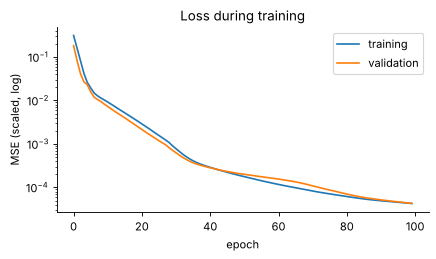

In [11]:
plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"], label="training")
plt.plot(history.history["val_loss"], label="validation")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (scaled, log)")
plt.title("Loss during training"); plt.legend(); plt.show()

<a id="evaluating-in-dollars"></a>

### Evaluating in Dollars

A scaled MSE of 0.0003 means nothing to a sales team. Convert predictions back with `scaler_y.inverse_transform` and
report the mean absolute error in dollars and R² on the untouched test set.

Then the important question: is the network worth it? A plain linear regression takes one line and no tuning.

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pred_nn = scaler_y.inverse_transform(model.predict(X_test_s, verbose=0))
linear = LinearRegression().fit(X_train, y_train)
pred_lin = linear.predict(X_test)

for name, pred in [("neural network", pred_nn), ("linear regression", pred_lin)]:
    print(f"{name:18} MAE ${mean_absolute_error(y_test, pred):>8,.0f}   R² {r2_score(y_test, pred):.4f}")

neural network     MAE $     379   R² 0.9966
linear regression  MAE $       1   R² 1.0000


The network is good, within a few hundred dollars on average. The linear model is perfect: an error of about one
dollar. This dataset was clearly generated from a linear formula of age, salary, net worth and debt, so the network has
nothing extra to find and can only approximate the straight line with its ReLU pieces. That's the
lesson worth taking from this project: **fit a simple baseline first**. A neural network earns its complexity only when
the relationship is genuinely non-linear, as it will be with images.

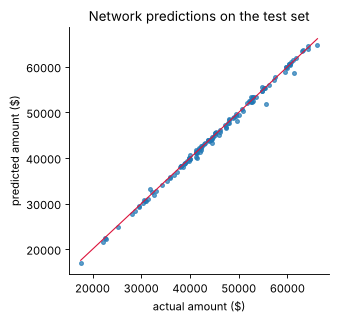

In [13]:
plt.figure(figsize=(4.2, 4))
plt.scatter(y_test, pred_nn, s=12, alpha=0.7)
lims = [y_test.values.min(), y_test.values.max()]
plt.plot(lims, lims, color="crimson", lw=1)
plt.xlabel("actual amount ($)"); plt.ylabel("predicted amount ($)")
plt.title("Network predictions on the test set"); plt.show()

<a id="predicting-for-a-new-customer"></a>

### Predicting for a New Customer

To score a new customer, pass the raw values through the **same fitted scaler**, predict, and invert the target
scaling. Hand-typing already-normalised numbers is error prone; let the scaler do it.

In [14]:
new_customer = pd.DataFrame([{"Gender": 1, "Age": 42, "Annual Salary": 70_000,
                              "Credit Card Debt": 9_000, "Net Worth": 450_000}])
amount = scaler_y.inverse_transform(model.predict(scaler_x.transform(new_customer), verbose=0))
print(f"expected purchase: ${amount[0, 0]:,.0f}")

expected purchase: $45,617


**Cheatsheet: tabular regression with Keras**

| Step | Code |
|---|---|
| Scale after splitting | `MinMaxScaler().fit(X_train)` then `.transform(X_test)` |
| Input layer | `keras.Input(shape=(n_features,))` |
| Regression output | `layers.Dense(1, activation="linear")` with `loss="mean_squared_error"` |
| Watch overfitting | `model.fit(..., validation_split=0.2)` then plot `history.history` |
| Back to real units | `scaler_y.inverse_transform(model.predict(X))` |
| Sanity check | Compare against `LinearRegression` |

#### Exercise 12

Add an `EarlyStopping` callback (a function Keras runs after every epoch) that watches `val_loss`, waits 10 epochs without improvement and restores the best
weights. Train for up to 500 epochs and print how many epochs actually ran and the test MAE in dollars.

#### Solution 12

*Try it yourself before running this cell.*

In [15]:
keras.utils.set_random_seed(0)
model_es = keras.Sequential([keras.Input(shape=(len(features),)),
                             layers.Dense(25, activation="relu"), layers.Dense(25, activation="relu"),
                             layers.Dense(1)])
model_es.compile(optimizer="adam", loss="mean_squared_error")
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
h = model_es.fit(X_train_s, y_train_s, epochs=500, batch_size=25, validation_split=0.2,
                 callbacks=[stop], verbose=0)
pred = scaler_y.inverse_transform(model_es.predict(X_test_s, verbose=0))
print("epochs run:", len(h.history["loss"]), f"| test MAE ${mean_absolute_error(y_test, pred):,.0f}")

epochs run: 321 | test MAE $71


<a id="19-how-convolutional-neural-networks-see"></a>

## 19. How Convolutional Neural Networks See

Images are just arrays of pixel values ([section 5](#images-are-just-arrays) showed one). A dense network treats an
image as a long list of unrelated numbers: a 32×32 colour image becomes 3,072 inputs, and
shifting the object by one pixel changes all of them. Convolutional networks keep the 2-D layout and learn small
pattern detectors that slide across the image, which is why they dominate image tasks.

<a id="convolution-sliding-feature-detectors"></a>

### Convolution: Sliding Feature Detectors

A **convolution** slides a small grid of weights, the **kernel** or filter (often 3×3 or 5×5), over the image. At each
position it multiplies the kernel with the patch underneath and sums the result into one number. The output grid is a
**feature map**: bright where the patch looks like the kernel's pattern.

A hand-made vertical-edge kernel lights up wherever brightness changes from left to right. In a CNN, nobody writes the
kernels: the network starts with random ones and learns them by backpropagation, exactly like the weights of a dense
layer. Early layers end up detecting edges and colours; deeper layers combine them into textures, parts and objects.

In [16]:
from matplotlib.animation import FuncAnimation, PillowWriter

def convolve2d(image, kernel):
    """'Valid' convolution (strictly cross-correlation, as in deep learning libraries)."""
    kh, kw = kernel.shape
    out = np.zeros((image.shape[0] - kh + 1, image.shape[1] - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = (image[i:i + kh, j:j + kw] * kernel).sum()
    return out

# A tiny 8x8 image: dark left half, bright right half, plus one bright pixel
small = np.zeros((8, 8)); small[:, 4:] = 1; small[2, 1] = 1
edge = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])           # vertical-edge detector
fmap = convolve2d(small, edge)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.4))
ax1.imshow(small, cmap="gray"); ax1.set_title("input with 3×3 kernel window")
rect = plt.Rectangle((-0.5, -0.5), 3, 3, fill=False, color="crimson", lw=3); ax1.add_patch(rect)
shown = np.full_like(fmap, np.nan)
im = ax2.imshow(shown, cmap="coolwarm", vmin=-3, vmax=3); ax2.set_title("feature map")
for ax in (ax1, ax2): ax.set_xticks([]); ax.set_yticks([])
positions = [(i, j) for i in range(fmap.shape[0]) for j in range(fmap.shape[1])]

def update(k):
    i, j = positions[k]
    rect.set_xy((j - 0.5, i - 0.5)); shown[i, j] = fmap[i, j]; im.set_data(shown)
    ax2.set_title(f"feature map: out[{i},{j}] = {fmap[i, j]:+.0f}")
    return rect, im

FuncAnimation(fig, update, frames=len(positions), interval=150).save(
    IMAGES / "convolution.gif", writer=PillowWriter(fps=6))
plt.close(fig)
print(fmap.astype(int))

[[ 0 -1  3  3  0  0]
 [ 0 -1  3  3  0  0]
 [ 0 -1  3  3  0  0]
 [ 0  0  3  3  0  0]
 [ 0  0  3  3  0  0]
 [ 0  0  3  3  0  0]]


![A 3×3 edge kernel sliding over an 8×8 image](images/convolution.gif)

The feature map is strongly positive exactly where dark meets bright, and the isolated bright pixel produces a
positive/negative pair on either side of it. A 3×3 kernel on an 8×8 image gives a 6×6 output; padding the input with
zeros (`padding="same"` in Keras) keeps the size unchanged.

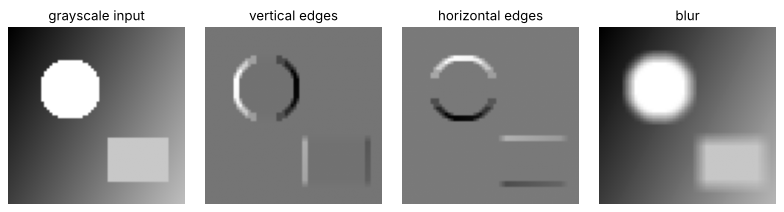

In [17]:
yy, xx = np.mgrid[0:64, 0:64]                                   # a small synthetic test image
gray = np.zeros((64, 64)) + xx * 2 + yy                         # smooth background gradient
gray[(xx - 22) ** 2 + (yy - 22) ** 2 < 120] = 255               # bright disc
gray[40:56, 36:58] = 200                                        # bright box
kernels = {"vertical edges": edge,
           "horizontal edges": edge.T,
           "blur": np.ones((5, 5)) / 25}

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("grayscale input")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    ax.imshow(convolve2d(gray, k), cmap="gray"); ax.set_title(name)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

<a id="relu-pooling-and-flattening"></a>

### ReLU, Pooling and Flattening

After each convolution comes a **ReLU**, which sets negative responses to zero and passes positive ones through. The
feature map becomes flat zeros with peaks where the pattern was found, which sharpens the signal and adds
non-linearity.

**Pooling** then downsamples each feature map. **Max pooling** keeps the largest value in every 2×2 block; **average
pooling** keeps the mean. Either halves the width and height, which:

- cuts the number of values (and so parameters and compute) in later layers by 4×,
- makes the network tolerant of small shifts: the peak survives even if it moves by a pixel,
- reduces overfitting.

Finally, **flattening** turns the stack of small feature maps into one long vector that feeds ordinary dense layers,
ending in a softmax over the classes.

In [18]:
feature = np.array([[ 7, -5,  2,  1],
                    [10,  2, -3, 17],
                    [-2,  0, 12, -8],
                    [ 4, -1,  3,  9]])
relu = np.maximum(0, feature)
blocks = relu.reshape(2, 2, 2, 2).swapaxes(1, 2)     # split into four 2x2 blocks
print("after ReLU:\n", relu)
print("max pool:\n", blocks.max(axis=(2, 3)))
print("average pool:\n", blocks.mean(axis=(2, 3)))
print("flattened:", blocks.max(axis=(2, 3)).ravel())

after ReLU:
 [[ 7  0  2  1]
 [10  2  0 17]
 [ 0  0 12  0]
 [ 4  0  3  9]]
max pool:
 [[10 17]
 [ 4 12]]
average pool:
 [[4.75 5.  ]
 [1.   6.  ]]
flattened: [10 17  4 12]


```mermaid
flowchart LR
    A["Image<br/>32×32×3"] --> B["Conv + ReLU<br/>learned filters"]
    B --> C["Pooling<br/>halve width/height"]
    C --> D["Conv + ReLU"]
    D --> E["Pooling"]
    E --> F["Flatten"]
    F --> G["Dense + ReLU<br/>(dropout)"]
    G --> H["Softmax<br/>class probabilities"]
```

**Dropout** randomly switches off a fraction of neurons at each training step (for example 40%). The network can't rely
on any single neuron, so it learns redundant, more general features. Dropout is active only during training; at
prediction time all neurons are used.

<a id="20-project-classifying-cifar-10-images"></a>

## 20. Project: Classifying CIFAR-10 Images

CIFAR-10 (from the Canadian Institute for Advanced Research) has 60,000 colour images of 32×32 pixels in ten classes:
airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. It's perfectly balanced, with 6,000 images per
class, split into 50,000 for training and 10,000 for testing. The images are tiny and blurry, which makes it a good
benchmark: easy to train on a laptop, hard to get near-perfect.

<a id="loading-the-images"></a>

### Loading the Images

`keras.datasets.cifar10.load_data()` downloads and caches the data. The loader below also accepts a local copy of the
official archive and, if neither is available, generates a small synthetic stand-in of coloured shapes so the rest of
the code still runs end to end.

In [19]:
import pickle, tarfile
import keras
from keras import layers
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                 # hide tf.function retracing notices

CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]


def read_cifar_tar(path):
    def batch(member):
        d = pickle.load(tar.extractfile(member), encoding="bytes")
        return d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1), np.array(d[b"labels"])
    with tarfile.open(path) as tar:
        names = sorted(m for m in tar.getnames() if "_batch" in m)
        train = [batch(n) for n in names if "data_batch" in n]
        X_te, y_te = batch(next(n for n in names if "test_batch" in n))
    return (np.concatenate([a for a, _ in train]), np.concatenate([b for _, b in train])), (X_te, y_te)


def make_stand_in(n_train=600, n_test=150, seed=0):
    """Ten classes of 32x32 colour shapes with random colour, position, size and noise."""
    g = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:32, 0:32]
    names = ["disc", "square", "triangle", "cross", "ring",
             "h-stripes", "v-stripes", "diagonal", "checker", "dots"]
    def draw(c):
        cx, cy, r = g.uniform(9, 23), g.uniform(9, 23), g.uniform(4, 9)
        dx, dy, s = xx - cx, yy - cy, g.integers(3, 6)
        mask = [dx**2 + dy**2 < r**2, (abs(dx) < r * .8) & (abs(dy) < r * .8),
                (dy > -r) & (dy < r) & (abs(dx) < (dy + r) / 2),
                (abs(dx) < r / 3.5) | (abs(dy) < r / 3.5),
                abs(np.hypot(dx, dy) - r) < 1.5,
                (yy // s) % 2 == 0, (xx // s) % 2 == 0, ((xx + yy) // s) % 2 == 0,
                ((xx // s) + (yy // s)) % 2 == 0, ((xx % (2 * s)) < 2) & ((yy % (2 * s)) < 2)][c]
        im = np.ones((32, 32, 3)) * g.uniform(0, 1, 3)          # random background colour
        im[mask] = g.uniform(0, 1, 3)                            # random (sometimes low-contrast) shape colour
        return (np.clip(im + g.normal(0, 0.3, im.shape), 0, 1) * 255).astype(np.uint8)
    def split(n):
        y = np.repeat(np.arange(10), n); g.shuffle(y)
        return np.stack([draw(c) for c in y]), y
    return split(n_train), split(n_test), names


def load_cifar10():
    archive = DATA / "cifar-10-python.tar.gz"
    if archive.exists():
        return read_cifar_tar(archive), CIFAR_CLASSES, True
    try:
        (X_tr, y_tr), (X_te, y_te) = keras.datasets.cifar10.load_data()
        return ((X_tr, y_tr.ravel()), (X_te, y_te.ravel())), CIFAR_CLASSES, True
    except Exception as exc:
        print(f"CIFAR-10 unavailable ({type(exc).__name__}); using a synthetic stand-in of 32x32 shapes.")
        train, test, names = make_stand_in()
        return (train, test), names, False


((X_train, y_train), (X_test, y_test)), class_names, real_cifar = load_cifar10()
print("train", X_train.shape, X_train.dtype, "| test", X_test.shape)
print("images per class:", np.bincount(y_train)[:5], "...")

CIFAR-10 unavailable (Exception); using a synthetic stand-in of 32x32 shapes.


train (6000, 32, 32, 3) uint8 | test (1500, 32, 32, 3)
images per class: [600 600 600 600 600] ...


In the environment where I generated these outputs, the download was blocked, so the results below come from the
synthetic stand-in: 6,000 noisy training images of ten shape and texture classes, with random colours that are
sometimes barely distinguishable from the background. With the real data, the same cells run unchanged; expect
roughly 70–75% test accuracy from this architecture after 10–20 epochs, and a few minutes per epoch on a CPU.

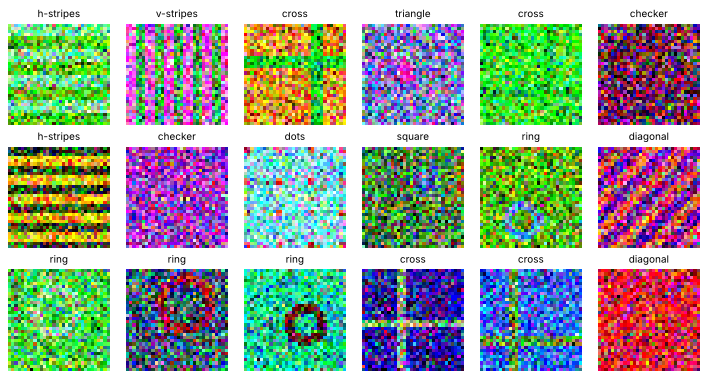

In [20]:
fig, axes = plt.subplots(3, 6, figsize=(9, 4.8))
for ax, i in zip(axes.ravel(), rng.choice(len(X_train), 18, replace=False)):
    ax.imshow(X_train[i]); ax.set_title(class_names[y_train[i]], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

<a id="preparing-images-and-labels"></a>

### Preparing Images and Labels

Two transformations:

- **Pixels to [0, 1]**: convert `uint8` to `float32` and divide by 255. Gradient descent behaves much better on small
  inputs.
- **Labels**: integer labels `0..9` work directly with the `sparse_categorical_crossentropy` loss. The alternative is
  one-hot encoding with `keras.utils.to_categorical` and plain `categorical_crossentropy`; the result is identical, the
  sparse form just saves memory.

In [21]:
X_train_f = X_train.astype("float32") / 255
X_test_f = X_test.astype("float32") / 255
input_shape = X_train_f.shape[1:]

print("input shape:", input_shape, "| pixel range:", X_train_f.min(), "to", X_train_f.max())
print("one-hot example:", y_train[0], "->", keras.utils.to_categorical(y_train[:1], 10)[0])

input shape: (32, 32, 3) | pixel range: 0.0 to 1.0
one-hot example: 7 -> [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


<a id="building-and-training-the-cnn"></a>

### Building and Training the CNN

The architecture is the classic VGG-style pattern: two 3×3 convolutions, pooling, dropout, then the same block with
twice the filters, then dense layers. I've halved the filter counts and dense width from the common 64/128/1024 version
so it trains in reasonable time on a CPU; the shape of the network is the same.

**Watch out:** older code passes `lr=0.001` to optimizers and uses lowercase `keras.optimizers.rmsprop`. In Keras 3
it's `keras.optimizers.RMSprop(learning_rate=0.001)`.

In [22]:
def build_cnn(input_shape, n_classes, augmentation=None):
    model = keras.Sequential([keras.Input(shape=input_shape)])
    if augmentation is not None:
        model.add(augmentation)                       # active only during training
    for filters in (32, 64):
        model.add(layers.Conv2D(filters, (3, 3), activation="relu", padding="same"))
        model.add(layers.Conv2D(filters, (3, 3), activation="relu"))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Dropout(0.3))
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(n_classes, activation="softmax"))
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


keras.utils.set_random_seed(42)
cnn = build_cnn(input_shape, len(class_names))
print(f"parameters: {cnn.count_params():,}")
history = cnn.fit(X_train_f, y_train, batch_size=64, epochs=16,
                  validation_split=0.1, shuffle=True, verbose=0)
for e in (0, 7, 15):
    print(f"epoch {e + 1}: accuracy {history.history['accuracy'][e]:.3f}, "
          f"val_accuracy {history.history['val_accuracy'][e]:.3f}")

parameters: 658,218


epoch 1: accuracy 0.121, val_accuracy 0.162
epoch 8: accuracy 0.662, val_accuracy 0.625
epoch 16: accuracy 0.843, val_accuracy 0.748


<a id="evaluating-with-a-confusion-matrix"></a>

### Evaluating with a Confusion Matrix

Accuracy alone hides which classes get mixed up. A **confusion matrix** counts, for each true class (rows), how often
each class was predicted (columns); the diagonal is the correct predictions.

**Watch out:** `model.predict_classes()` was removed. Use `np.argmax(model.predict(X), axis=1)` for softmax outputs.

test accuracy: 0.760


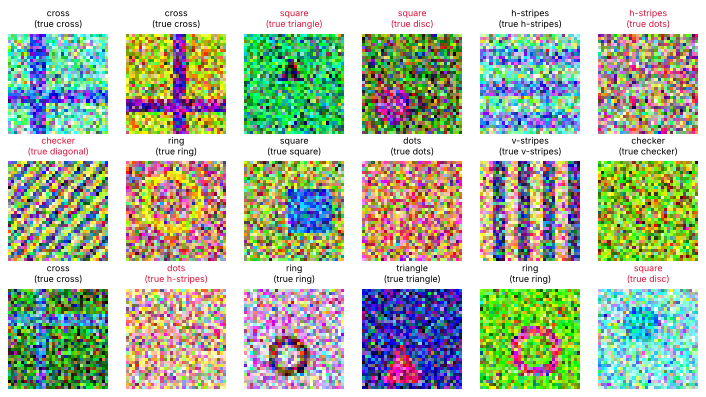

In [23]:
from sklearn.metrics import confusion_matrix

test_loss, test_acc = cnn.evaluate(X_test_f, y_test, verbose=0)
predicted = np.argmax(cnn.predict(X_test_f, verbose=0), axis=1)
print(f"test accuracy: {test_acc:.3f}")

fig, axes = plt.subplots(3, 6, figsize=(9, 5))
for ax, i in zip(axes.ravel(), range(18)):
    ax.imshow(X_test[i]); ax.axis("off")
    ok = predicted[i] == y_test[i]
    ax.set_title(f"{class_names[predicted[i]]}\n(true {class_names[y_test[i]]})", fontsize=8,
                 color="black" if ok else "crimson")
plt.tight_layout(); plt.show()

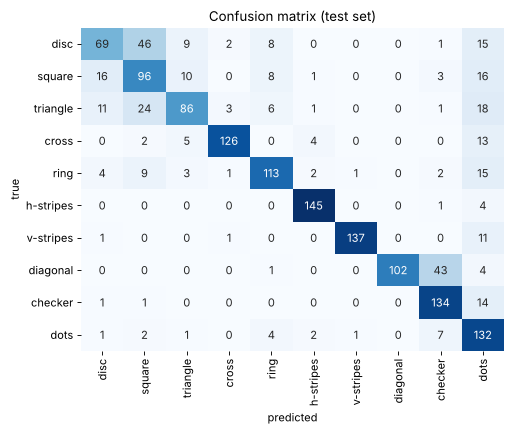

In [24]:
cm = confusion_matrix(y_test, predicted)
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

<a id="saving-and-reloading-the-model"></a>

### Saving and Reloading the Model

A trained model is architecture plus weights plus optimizer state. Save it in the native `.keras` format, which is a
single zip file; reloading gives back a model that predicts identically and can continue training.

**Watch out:** the old `.h5` (HDF5) format still loads but is legacy in Keras 3. Use `.keras` for new models.

In [25]:
path = MODELS / "cifar10-cnn.keras"
cnn.save(path)
reloaded = keras.models.load_model(path)
same = np.allclose(reloaded.predict(X_test_f[:50], verbose=0), cnn.predict(X_test_f[:50], verbose=0))
print(path, f"{path.stat().st_size / 1e6:.1f} MB | identical predictions after reload: {same}")

models/cifar10-cnn.keras 5.3 MB | identical predictions after reload: True


<a id="improving-generalisation-with-image-augmentation"></a>

### Improving Generalisation with Image Augmentation

Augmentation creates new training variations of the images we already have: flipped, rotated, shifted, zoomed, with
changed contrast. The model never sees exactly the same image twice, so it has to learn what makes a class a class
rather than memorising pixels. It's like giving a child many different views of the same object.

In Keras 3 augmentation is done with preprocessing layers. Put them at the start of the model and they run on the fly,
only during training.

**Watch out:** `ImageDataGenerator`, `model.fit_generator()` and `scipy.misc.toimage` all appear in older tutorials. The
first is deprecated, the other two are gone. Preprocessing layers plus a normal `model.fit()` replace them.

Choose augmentations that keep the label true. Horizontal flips are fine for animals and vehicles; vertical flips and
90° rotations produce upside-down cars and are usually harmful. For traffic signs, even horizontal flips are wrong:
"turn left" becomes "turn right".

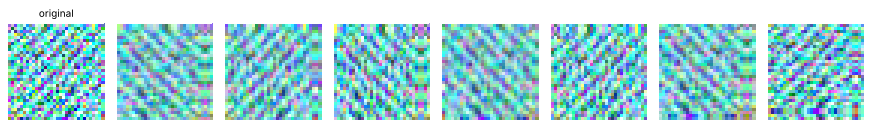

In [26]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),        # shift up to 10% in each direction
    layers.RandomContrast(0.2),
], name="augmentation")

sample = X_train_f[:1]
fig, axes = plt.subplots(1, 8, figsize=(11, 1.8))
axes[0].imshow(sample[0]); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(np.clip(augment(sample, training=True)[0], 0, 1))
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In [27]:
keras.utils.set_random_seed(42)
cnn_aug = build_cnn(input_shape, len(class_names), augmentation=augment)
cnn_aug.fit(X_train_f, y_train, batch_size=64, epochs=16, validation_split=0.1, verbose=0)
_, aug_acc = cnn_aug.evaluate(X_test_f, y_test, verbose=0)
print(f"test accuracy without augmentation: {test_acc:.3f} | with augmentation: {aug_acc:.3f}")
cnn_aug.save(MODELS / "cifar10-cnn-augmented.keras")

test accuracy without augmentation: 0.760 | with augmentation: 0.819


Augmentation lifts test accuracy by a few points here. Two things I learned getting there. First, augmentation needs
more epochs to pay off, because every epoch is harder; after 8 epochs the augmented model was still behind. Second, my
first version also used `RandomRotation(0.08)`, and accuracy dropped sharply: a 30° turn makes horizontal stripes look
diagonal, so the augmentation was changing labels. For real CIFAR-10 photos, small rotations are safe and usually
help; the rule is the same either way: only use transformations that keep the label true.

**Cheatsheet: image classification with Keras**

| Step | Code |
|---|---|
| Built-in dataset | `keras.datasets.cifar10.load_data()` |
| Scale pixels | `X.astype("float32") / 255` |
| Integer labels | `loss="sparse_categorical_crossentropy"` |
| Conv block | `layers.Conv2D(32, (3, 3), activation="relu")`, `layers.MaxPooling2D((2, 2))`, `layers.Dropout(0.3)` |
| Class predictions | `np.argmax(model.predict(X), axis=1)` |
| Augmentation | `layers.RandomFlip`, `RandomTranslation`, `RandomRotation`, `RandomContrast` at the start of the model (label-preserving only) |
| Save / load | `model.save("m.keras")`, `keras.models.load_model("m.keras")` |

#### Exercise 13

Add `layers.BatchNormalization()` after every `Conv2D` layer (you'll need a copy of `build_cnn`). Train for the same 16
epochs and compare test accuracy with the plain model.

#### Solution 13

*Try it yourself before running this cell.*

In [28]:
def build_cnn_bn(input_shape, n_classes):
    model = keras.Sequential([keras.Input(shape=input_shape)])
    for filters in (32, 64):
        for pad in ("same", "valid"):
            model.add(layers.Conv2D(filters, (3, 3), activation="relu", padding=pad))
            model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2))); model.add(layers.Dropout(0.3))
    model.add(layers.Flatten()); model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(0.3)); model.add(layers.Dense(n_classes, activation="softmax"))
    model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

keras.utils.set_random_seed(42)
cnn_bn = build_cnn_bn(input_shape, len(class_names))
cnn_bn.fit(X_train_f, y_train, batch_size=64, epochs=16, validation_split=0.1, verbose=0)
print(f"plain {test_acc:.3f} | batch norm {cnn_bn.evaluate(X_test_f, y_test, verbose=0)[1]:.3f}")

plain 0.760 | batch norm 0.794


<a id="21-project-recognising-traffic-signs-with-lenet"></a>

## 21. Project: Recognising Traffic Signs with LeNet

A self-driving car has to read traffic signs reliably. The German Traffic Sign Recognition Benchmark (GTSRB) has more
than 50,000 photos of 43 sign types, cropped and resized to 32×32. We'll classify them with **LeNet-5**, one of the first
successful CNNs (Yann LeCun's 1998 network for handwritten digits). It's tiny by modern standards, which makes it fast
to train on a CPU, and it still does very well here.

<a id="loading-the-pickled-splits"></a>

### Loading the Pickled Splits

The data comes as three pickled dictionaries, already split into training, validation and test sets. The 43 class
names follow the benchmark's standard numbering.

In [29]:
SIGN_NAMES = ["Speed limit 20", "Speed limit 30", "Speed limit 50", "Speed limit 60", "Speed limit 70",
    "Speed limit 80", "End speed limit 80", "Speed limit 100", "Speed limit 120", "No passing",
    "No passing >3.5t", "Right-of-way next intersection", "Priority road", "Yield", "Stop", "No vehicles",
    "Vehicles >3.5t prohibited", "No entry", "General caution", "Dangerous curve left",
    "Dangerous curve right", "Double curve", "Bumpy road", "Slippery road", "Road narrows right",
    "Road work", "Traffic signals", "Pedestrians", "Children crossing", "Bicycles crossing",
    "Beware ice/snow", "Wild animals crossing", "End all limits", "Turn right ahead", "Turn left ahead",
    "Ahead only", "Straight or right", "Straight or left", "Keep right", "Keep left",
    "Roundabout mandatory", "End no passing", "End no passing >3.5t"]

SIGNS = DATA / "traffic-signs"
if not (SIGNS / "train.p").exists():
    raise FileNotFoundError("Put train.p, valid.p and test.p in data/traffic-signs/ (see Setup).")

def load_split(name):
    with open(SIGNS / f"{name}.p", "rb") as f:
        d = pickle.load(f)
    return d["features"], d["labels"]

X_train, y_train = load_split("train")
X_valid, y_valid = load_split("valid")
X_test, y_test = load_split("test")
print("train", X_train.shape, "| valid", X_valid.shape, "| test", X_test.shape, "| classes", len(np.unique(y_train)))

train (34799, 32, 32, 3) | valid (4410, 32, 32, 3) | test (12630, 32, 32, 3) | classes 43


most common: Speed limit 50 (2010), rarest: Speed limit 20 (180)
labels at positions 0, 5000, 10000, 20000: [41 37  0 35] (the file is sorted by class)


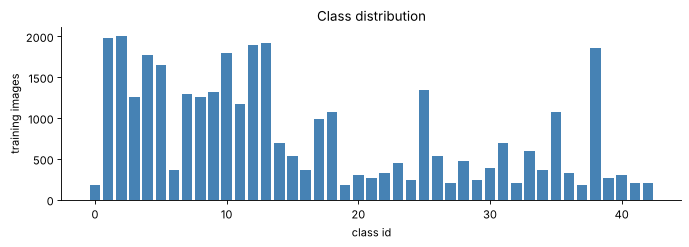

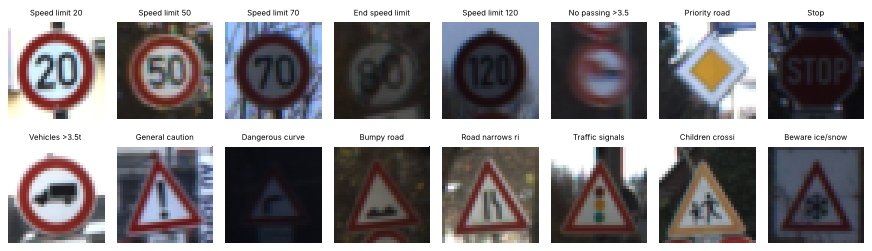

In [30]:
counts = np.bincount(y_train)
print(f"most common: {SIGN_NAMES[counts.argmax()]} ({counts.max()}), "
      f"rarest: {SIGN_NAMES[counts.argmin()]} ({counts.min()})")
print("labels at positions 0, 5000, 10000, 20000:", y_train[[0, 5000, 10000, 20000]], "(the file is sorted by class)")

plt.figure(figsize=(10, 2.8))
plt.bar(range(43), counts, color="steelblue")
plt.xlabel("class id"); plt.ylabel("training images"); plt.title("Class distribution"); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for ax, c in zip(axes.ravel(), range(0, 43, 43 // 16 + 0)):
    ax.imshow(X_train[np.flatnonzero(y_train == c)[20]]); ax.axis("off")
    ax.set_title(SIGN_NAMES[c][:15], fontsize=7)
plt.tight_layout(); plt.show()

Two things stand out. The classes are **imbalanced**: some signs have ten times more images than others, so a model can
look accurate while neglecting rare signs. And the training file is **sorted by class**, so it must be shuffled before
training. Keras shuffles each epoch by default, but if you take a validation split from the end of an unshuffled array
you'd validate on only the last few classes.

<a id="grayscale-and-normalisation"></a>

### Grayscale and Normalisation

Two preprocessing steps from the original LeNet experiments on this data:

- **Grayscale**: averaging the three channels gives one channel. Sign shapes and symbols carry most of the information,
  and the network has a third of the input to process.
- **Normalisation**: `(pixel - 128) / 128` maps 0..255 to roughly −1..1, centred on zero, which speeds up training.

shape (34799, 32, 32, 1) | range -0.97 to 0.99


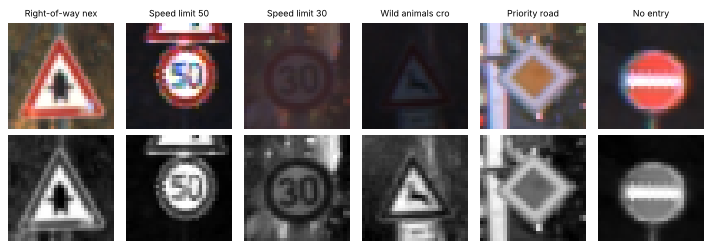

In [31]:
from sklearn.utils import shuffle

X_train, y_train = shuffle(X_train, y_train, random_state=42)

def preprocess(X):
    gray = X.mean(axis=3, keepdims=True)         # same as summing the channels / 3
    return ((gray - 128) / 128).astype("float32")

X_train_g, X_valid_g, X_test_g = preprocess(X_train), preprocess(X_valid), preprocess(X_test)
print("shape", X_train_g.shape, "| range", X_train_g.min().round(2), "to", X_train_g.max().round(2))

fig, axes = plt.subplots(2, 6, figsize=(9, 3.2))
for k, i in enumerate(range(6)):
    axes[0, k].imshow(X_train[i]); axes[0, k].set_title(SIGN_NAMES[y_train[i]][:16], fontsize=8)
    axes[1, k].imshow(X_train_g[i].squeeze(), cmap="gray")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

<a id="the-lenet-5-architecture"></a>

### The LeNet-5 Architecture

LeNet alternates convolution and average pooling twice, then uses three dense layers:

```mermaid
flowchart LR
    A["Input<br/>32×32×1"] --> B["Conv 6 @5×5<br/>→ 28×28×6"]
    B --> C["AvgPool 2×2<br/>→ 14×14×6"]
    C --> D["Conv 16 @5×5<br/>→ 10×10×16"]
    D --> E["AvgPool 2×2<br/>→ 5×5×16"]
    E --> F["Flatten<br/>400"]
    F --> G["Dense 120"]
    G --> H["Dense 84"]
    H --> I["Softmax 43"]
```

Each 5×5 convolution without padding shrinks the map by 4 pixels; each pooling halves it. The whole network has about
65,000 parameters, against hundreds of thousands for the CIFAR model.

**Watch out:** older code uses `nb_epoch=`, `Adam(lr=...)` and reads `history.history['acc']`. In Keras 3 those are
`epochs=`, `learning_rate=` and `'accuracy'`.

In [32]:
keras.utils.set_random_seed(42)
lenet = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),
    layers.Conv2D(6, (5, 5), activation="relu"),
    layers.AveragePooling2D((2, 2)),
    layers.Conv2D(16, (5, 5), activation="relu"),
    layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(120, activation="relu"),
    layers.Dense(84, activation="relu"),
    layers.Dense(43, activation="softmax"),
])
lenet.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"parameters: {lenet.count_params():,}")

history = lenet.fit(X_train_g, y_train, batch_size=500, epochs=30,
                    validation_data=(X_valid_g, y_valid), verbose=0)
h = history.history
print(f"after 30 epochs: train accuracy {h['accuracy'][-1]:.3f}, validation accuracy {h['val_accuracy'][-1]:.3f}")

parameters: 64,511


after 30 epochs: train accuracy 0.991, validation accuracy 0.848


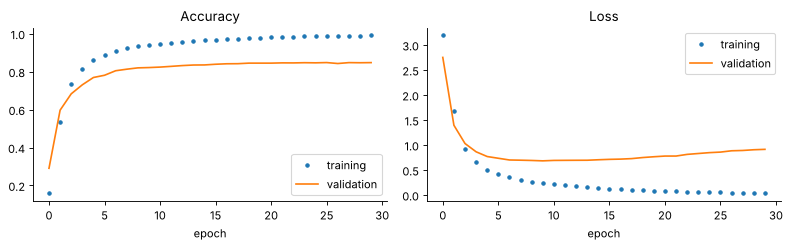

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
ax1.plot(h["accuracy"], "o", ms=3, label="training"); ax1.plot(h["val_accuracy"], label="validation")
ax1.set_title("Accuracy"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(h["loss"], "o", ms=3, label="training"); ax2.plot(h["val_loss"], label="validation")
ax2.set_title("Loss"); ax2.set_xlabel("epoch"); ax2.legend()
plt.tight_layout(); plt.show()

Training accuracy reaches 99% while validation accuracy levels off around 85%, and validation loss stops improving
after the first few epochs: the network is overfitting. Part of the gap is also a distribution shift, because the
validation and test photos come from different recording sessions than the training ones. That gap is what the exercise at the end of this section tackles.

<a id="test-accuracy-and-the-classes-it-confuses"></a>

### Test Accuracy and the Classes It Confuses

With 43 classes, an annotated confusion matrix is unreadable, so we plot it as a heatmap and then list the most frequent
mistakes. Per-class recall shows which signs the model struggles with.

In [34]:
from sklearn.metrics import classification_report

pred = np.argmax(lenet.predict(X_test_g, verbose=0), axis=1)
print(f"test accuracy: {(pred == y_test).mean():.3f}")

cm = confusion_matrix(y_test, pred)
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
print("most common mistakes:")
for t, p in top:
    print(f"  {off[t, p]:3d} x  {SIGN_NAMES[t]}  ->  {SIGN_NAMES[p]}")

test accuracy: 0.851
most common mistakes:
   84 x  Speed limit 80  ->  Speed limit 50
   55 x  Speed limit 70  ->  Speed limit 30
   52 x  Speed limit 50  ->  Speed limit 30
   45 x  Speed limit 20  ->  Speed limit 30
   40 x  Speed limit 100  ->  Speed limit 120


lowest recall: Speed limit 20 0.23, Double curve 0.36, Road narrows right 0.49, Pedestrians 0.50, Dangerous curve left 0.57


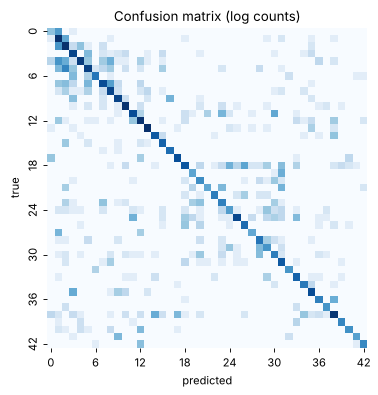

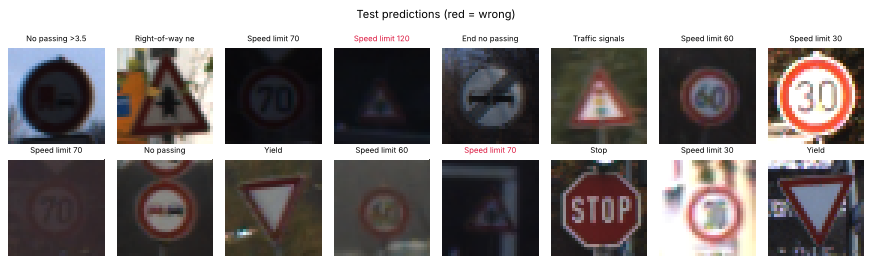

In [35]:
recall = cm.diagonal() / cm.sum(axis=1)
worst = np.argsort(recall)[:5]
print("lowest recall:", ", ".join(f"{SIGN_NAMES[c]} {recall[c]:.2f}" for c in worst))

plt.figure(figsize=(6, 5.2))
sns.heatmap(np.log1p(cm), cmap="Blues", cbar=False, square=True, xticklabels=6, yticklabels=6)
plt.title("Confusion matrix (log counts)"); plt.xlabel("predicted"); plt.ylabel("true"); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for ax, i in zip(axes.ravel(), rng.choice(len(X_test), 16, replace=False)):
    ax.imshow(X_test[i]); ax.axis("off")
    ax.set_title(SIGN_NAMES[pred[i]][:15], fontsize=7, color="black" if pred[i] == y_test[i] else "crimson")
plt.suptitle("Test predictions (red = wrong)", fontsize=10); plt.tight_layout(); plt.show()

The mistakes are the ones a person would expect: speed limits confused with other speed limits (the digits are small at
32×32), and warning triangles with similar pictograms mixed up with each other.

**Cheatsheet: small CNNs and LeNet**

| Step | Code |
|---|---|
| Shuffle sorted data | `X, y = sklearn.utils.shuffle(X, y)` |
| Grayscale | `X.mean(axis=3, keepdims=True)` |
| Centre and scale | `(X - 128) / 128` |
| Separate validation set | `model.fit(..., validation_data=(X_val, y_val))` |
| Largest errors | zero the confusion matrix diagonal, then `np.argsort` |
| Per-class recall | `cm.diagonal() / cm.sum(axis=1)` |

#### Exercise 14

Reduce LeNet's overfitting. Add `layers.Dropout(0.3)` after each of the two hidden dense layers, train for 30 epochs
with the same settings, and compare validation and test accuracy with the original.

#### Solution 14

*Try it yourself before running this cell.*

In [36]:
keras.utils.set_random_seed(42)
lenet_drop = keras.Sequential([
    keras.Input(shape=(32, 32, 1)),
    layers.Conv2D(6, (5, 5), activation="relu"), layers.AveragePooling2D((2, 2)),
    layers.Conv2D(16, (5, 5), activation="relu"), layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(120, activation="relu"), layers.Dropout(0.3),
    layers.Dense(84, activation="relu"), layers.Dropout(0.3),
    layers.Dense(43, activation="softmax"),
])
lenet_drop.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hd = lenet_drop.fit(X_train_g, y_train, batch_size=500, epochs=30,
                    validation_data=(X_valid_g, y_valid), verbose=0).history
acc = (np.argmax(lenet_drop.predict(X_test_g, verbose=0), axis=1) == y_test).mean()
print(f"validation {hd['val_accuracy'][-1]:.3f} (was {h['val_accuracy'][-1]:.3f}) | "
      f"test {acc:.3f} (was {(pred == y_test).mean():.3f})")

validation 0.931 (was 0.848) | test 0.913 (was 0.851)


<a id="22-project-recognising-dog-breeds-with-transfer-learning"></a>

## 22. Project: Recognising Dog Breeds with Transfer Learning

The capstone: a classifier for 120 dog breeds from real photos. The CNNs in the last two projects were trained from
scratch on tiny 32×32 images. Photos are larger and more varied, and training a network from scratch for them takes
far more data and compute than we have. **Transfer learning** borrows a network someone else already trained.

<a id="neural-networks-tensorflow-and-transfer-learning"></a>

### Neural Networks, TensorFlow and Transfer Learning

Neural networks need a numerical library built for speed. **TensorFlow** is Google's open-source library
for fast numerical computing on GPUs and TPUs, and **Keras** is its high-level API. Since Keras 3, Keras can also run on JAX
or PyTorch.

Training an image model from scratch takes millions of images and a lot of compute. **Transfer learning** sidesteps that.
You take a network already trained on ImageNet (1.4 million images, 1,000 classes), keep its feature-extracting layers
frozen, and train only a small new output layer for your own classes.

```mermaid
flowchart LR
    I["Image (224 × 224 × 3)"] --> B["Pretrained base: EfficientNetV2B0<br/>frozen, learned on ImageNet"]
    B --> V["Feature vector (1,280 numbers)"] --> D["New Dense layer + softmax<br/>trained on our breeds"] --> P["Probability per breed"]
```

A **GPU** runs the matrix maths inside neural networks in parallel, which makes training 10–30× faster than on a CPU.
Google Colab offers free GPUs (*Runtime → Change runtime type*). On Apple Silicon, `tensorflow-metal` uses the local GPU.

> **About the outputs in this section.** The machine that produced this post couldn't download the Stanford Dogs images or
> the pretrained ImageNet weights, so the code fell back to a tiny generated stand-in dataset and untrained weights. The
> outputs below show the pipeline running end to end, **not** real accuracy. With an internet connection (and ideally a
> GPU), the same code downloads the real data and weights.

In [37]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: False


<a id="getting-the-images"></a>

### Getting the Images

The **Stanford Dogs** dataset has 20,580 images of 120 breeds, one folder per breed. That layout makes loading
straightforward. Before training, check the data matches your expectations: count the images per class and look at a few.

In [38]:
# Download Stanford Dogs (~750 MB). If that isn't possible, build a tiny stand-in dataset so the pipeline still runs.
import tarfile
import tensorflow as tf
from PIL import Image

DOGS_DIR = DATA / "stanford-dogs" / "Images"
USING_STAND_IN = False
if not DOGS_DIR.exists():
    try:
        tar_path = tf.keras.utils.get_file(
            "images.tar", "http://vision.stanford.edu/aditya86/ImageNetDogs/images.tar", cache_dir=".")
        with tarfile.open(tar_path) as tar:
            tar.extractall(DATA / "stanford-dogs")
    except Exception as err:                                  # offline / blocked: generate stand-in images
        print("Could not download Stanford Dogs:", type(err).__name__)
        USING_STAND_IN = True
        DOGS_DIR = DATA / "stand-in-dogs"
        rng = np.random.default_rng(42)
        for i, breed in enumerate(["n0000-beagle", "n0001-boxer", "n0002-collie", "n0003-pug", "n0004-whippet"]):
            (DOGS_DIR / breed).mkdir(parents=True, exist_ok=True)
            tint = np.array([40 * i + 40, 200 - 30 * i, 120 + 25 * i])
            for j in range(40):
                noise = rng.integers(0, 80, size=(160, 160, 3))
                Image.fromarray(np.clip(noise + tint, 0, 255).astype("uint8")).save(DOGS_DIR / breed / f"{j}.jpg")

breed_dirs = sorted(p for p in DOGS_DIR.iterdir() if p.is_dir())
counts = pd.Series({p.name.split("-", 1)[1]: len(list(p.glob("*.jpg"))) for p in breed_dirs})
print(f"{'STAND-IN DATA — ' if USING_STAND_IN else ''}{len(breed_dirs)} classes, {counts.sum()} images")
print(counts.describe().round(1))

Could not download Stanford Dogs: Exception


STAND-IN DATA — 5 classes, 200 images
count     5.0
mean     40.0
std       0.0
min      40.0
25%      40.0
50%      40.0
75%      40.0
max      40.0
dtype: float64


<a id="from-files-to-batches-of-tensors"></a>

### From Files to Batches of Tensors

A **tensor** is like a NumPy array that can live on a GPU. Each image becomes a tensor of shape `(224, 224, 3)`. That's the
size the pretrained model expects, and every image in a batch must share one shape.

`tf.keras.utils.image_dataset_from_directory` does the heavy lifting in one call:

- reads and decodes the image files and resizes them to 224 × 224,
- infers labels from folder names, one-hot encoded with `label_mode="categorical"`,
- splits off a validation set (`validation_split` with `subset="both"`),
- groups images into **batches** of 32 and shuffles the training data.

Add `.prefetch(tf.data.AUTOTUNE)` so loading the next batch overlaps with training on the current one.

**Watch out:** EfficientNetV2 models in `tf.keras.applications` include their own rescaling layer and expect raw 0–255
pixels, so don't divide by 255 yourself. Always check what preprocessing a pretrained model expects.

In [39]:
import tensorflow as tf

IMG_SIZE, BATCH_SIZE = (224, 224), 32
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    DOGS_DIR, label_mode="categorical", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    validation_split=0.2, subset="both", seed=42)
class_names = [name.split("-", 1)[1] for name in train_ds.class_names]

images, labels = next(iter(train_ds))
print("image batch:", images.shape, images.dtype, "| label batch:", labels.shape)
print("first label (one-hot):", labels[0].numpy().astype(int), "->", class_names[int(np.argmax(labels[0]))])

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
valid_ds = valid_ds.prefetch(AUTOTUNE)

Found 200 files belonging to 5 classes.


Using 160 files for training.


Using 40 files for validation.


image batch: (32, 224, 224, 3) <dtype: 'float32'> | label batch: (32, 5)
first label (one-hot): [0 0 1 0 0] -> collie


Always look at a batch before training. It's the cheapest way to catch a preprocessing bug.

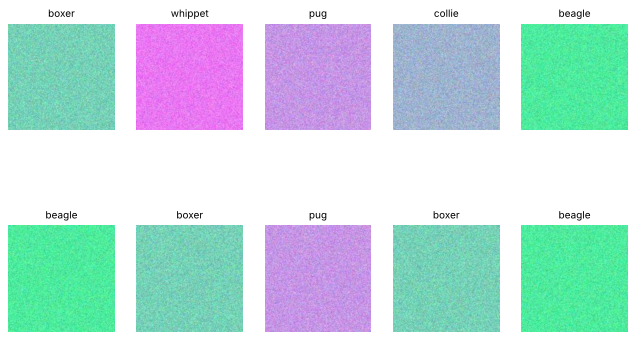

In [40]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(min(10, len(images))):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[int(np.argmax(labels[i]))], fontsize=9)
    plt.axis("off")
plt.show()

<a id="building-the-model"></a>

### Building the Model

The model is the frozen pretrained base plus one new `Dense` layer with **softmax** activation, which turns the outputs into
probabilities between 0 and 1 that sum to 1.

Compiling sets three things:

- a **loss** that measures how wrong the model is: `CategoricalCrossentropy` for one-hot labels,
- an **optimizer** that decides how to adjust the weights to reduce the loss: `Adam` is a reliable default,
- **metrics** to report, such as `accuracy`.

The Functional API (`inputs → base → outputs`) is used here because it scales to more complex architectures. The `try` block
falls back to untrained weights only if the ImageNet weights can't be downloaded.

In [41]:
import tensorflow as tf

NUM_CLASSES = len(class_names)

def create_model(num_classes=NUM_CLASSES, img_size=IMG_SIZE):
    """Frozen EfficientNetV2B0 feature extractor + a softmax classification head."""
    try:
        base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet",
                                                      input_shape=img_size + (3,), pooling="avg")
    except Exception as err:                       # weights not downloadable: same architecture, untrained
        print("ImageNet weights unavailable (", type(err).__name__, ") - using untrained weights for a dry run.")
        base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights=None,
                                                      input_shape=img_size + (3,), pooling="avg")
    base.trainable = False                         # transfer learning: keep the pretrained features

    inputs = tf.keras.Input(shape=img_size + (3,), name="input_layer")
    x = base(inputs, training=False)               # 0-255 pixels in; the model rescales internally
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", name="output_layer")(x)
    model = tf.keras.Model(inputs, outputs, name="dog_vision")
    model.compile(loss=tf.keras.losses.CategoricalCrossentropy(),
                  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  metrics=["accuracy"])
    return model

model = create_model()
model.summary(show_trainable=True)

ImageNet weights unavailable ( Exception ) - using untrained weights for a dry run.


Model: "dog_vision"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetv2-b0           │ (None, 1280)          │  5,919,312 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ output_layer (Dense)        │ (None, 5)             │      6,405 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 5,925,717 (22.60 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 5,919,312 (22.58 MB)

<a id="training-with-callbacks"></a>

### Training with Callbacks

**Callbacks** run during training. **EarlyStopping** (used in the car-purchase exercise) halts training when the
validation metric stops improving and restores the best weights. **TensorBoard** logs metrics so you can watch the
curves live (`%load_ext tensorboard`, then `%tensorboard --logdir logs`).

Start with a small subset so you know the pipeline works before you spend GPU time.

Epoch 1/2


5/5 - 16s - 3s/step - accuracy: 0.1875 - loss: 1.6101 - val_accuracy: 0.1250 - val_loss: 1.6100


Epoch 2/2


5/5 - 3s - 640ms/step - accuracy: 0.2188 - loss: 1.6056 - val_accuracy: 0.1250 - val_loss: 1.6089


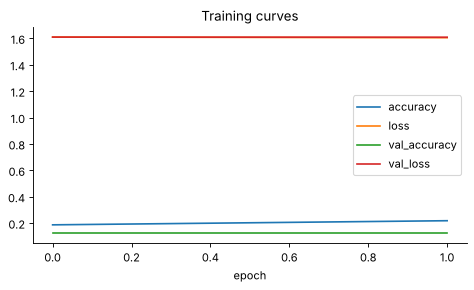

In [42]:
import datetime
import tensorflow as tf

log_dir = Path("logs") / datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
callbacks = [tf.keras.callbacks.TensorBoard(log_dir=str(log_dir)),
             tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)]

EPOCHS = 2 if USING_STAND_IN else 10
history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2)

pd.DataFrame(history.history).plot(figsize=(7, 3.5), title="Training curves"); plt.xlabel("epoch"); plt.show()

<a id="turning-probabilities-into-predictions"></a>

### Turning Probabilities into Predictions

`model.predict` returns a probability for every class for every image. `argmax` picks the most likely class index, which
maps back to a breed name.

In [43]:
pred_probs = model.predict(valid_ds, verbose=0)
y_true = np.concatenate([np.argmax(labels, axis=1) for _, labels in valid_ds])
y_pred = pred_probs.argmax(axis=1)

def get_pred_label(probabilities):
    """Turn one row of prediction probabilities into a breed name."""
    return class_names[int(np.argmax(probabilities))]

print("probabilities shape:", pred_probs.shape)
print("first image: predicted", get_pred_label(pred_probs[0]), f"({pred_probs[0].max():.2f}) | actual",
      class_names[y_true[0]])
print("validation accuracy:", round(float((y_pred == y_true).mean()), 3))

probabilities shape: (40, 5)
first image: predicted beagle (0.20) | actual whippet
validation accuracy: 0.125


Visualizing predictions makes them understandable to anyone. The cell shows each image with its predicted label and
confidence (green if right, red if wrong) above a bar chart of the top-10 probabilities. With 120 classes, per-class accuracy
and a confusion matrix reveal which breeds get mixed up, usually the ones that look alike.

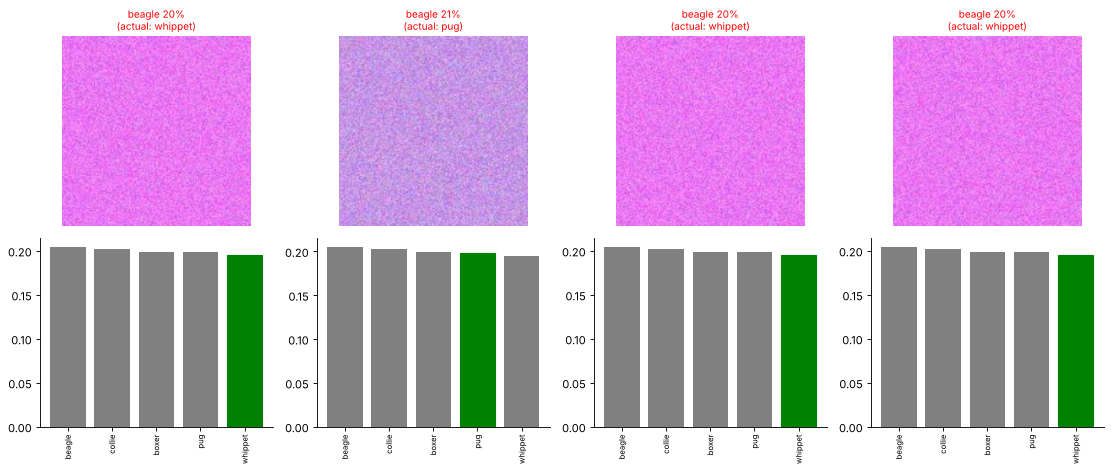

accuracy per class:
 boxer      0.0
collie     0.0
pug        0.0
whippet    0.0
beagle     1.0
dtype: float64


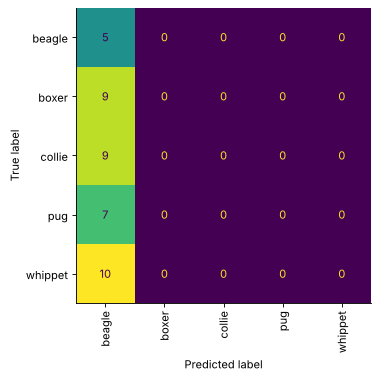

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay

images = np.concatenate([batch for batch, _ in valid_ds])
fig = plt.figure(figsize=(14, 6))
for i in range(min(4, len(images))):
    ax = fig.add_subplot(2, 4, i + 1)
    ax.imshow(images[i].astype("uint8")); ax.axis("off")
    colour = "green" if y_pred[i] == y_true[i] else "red"
    ax.set_title(f"{class_names[y_pred[i]]} {pred_probs[i].max():.0%}\n(actual: {class_names[y_true[i]]})",
                 color=colour, fontsize=9)
    top = np.argsort(pred_probs[i])[::-1][:10]
    ax2 = fig.add_subplot(2, 4, i + 5)
    bars = ax2.bar(range(len(top)), pred_probs[i][top], color="grey")
    if y_true[i] in top:
        bars[list(top).index(y_true[i])].set_color("green")
    ax2.set_xticks(range(len(top)), [class_names[t] for t in top], rotation=90, fontsize=7)
plt.tight_layout(); plt.show()

per_class = pd.Series(y_pred == y_true).groupby(y_true).mean().rename(index=dict(enumerate(class_names)))
print("accuracy per class:\n", per_class.round(2).sort_values().head())
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=class_names, xticks_rotation=90,
                                        colorbar=False)
plt.show()

<a id="saving-loading-and-predicting-on-new-images"></a>

### Saving, Loading and Predicting on New Images

Saving works exactly as for the [CIFAR-10 model](#saving-and-reloading-the-model): one `.keras` file, reloaded and
checked for identical predictions. Then the real test, photos the model has never seen.

In [45]:
import tensorflow as tf

model_path = "dog-vision-model.keras"
model.save(model_path)
loaded_model = tf.keras.models.load_model(model_path)
print("Loaded model gives identical predictions:",
      np.allclose(loaded_model.predict(valid_ds.take(1), verbose=0), model.predict(valid_ds.take(1), verbose=0)))

Loaded model gives identical predictions: True


Competitions such as Kaggle's *Dog Breed Identification* expect one row per test image, with an `id` column plus one
probability column per breed:

In [46]:
# Kaggle-style submission: one row per image, one probability column per class.
image_ids = [f"image_{i}" for i in range(len(pred_probs))]       # with Kaggle data: the test file names
submission = pd.DataFrame(pred_probs, columns=class_names)
submission.insert(0, "id", image_ids)
submission.to_csv("dog-vision-submission.csv", index=False)
print(submission.iloc[:3, :6].round(3))

        id  beagle  boxer  collie    pug  whippet
0  image_0   0.205  0.199   0.202  0.198    0.196
1  image_1   0.206  0.199   0.203  0.198    0.195
2  image_2   0.205  0.199   0.202  0.198    0.196


The final test is your own photos. Load each file, resize it to the model's input size, stack the images into a batch, and
predict. One of the four test images is a person, which is a useful reminder that a classifier always answers with one of
the classes it knows, however unlike them the input is. Production systems usually add an "unknown" class or a confidence
threshold.

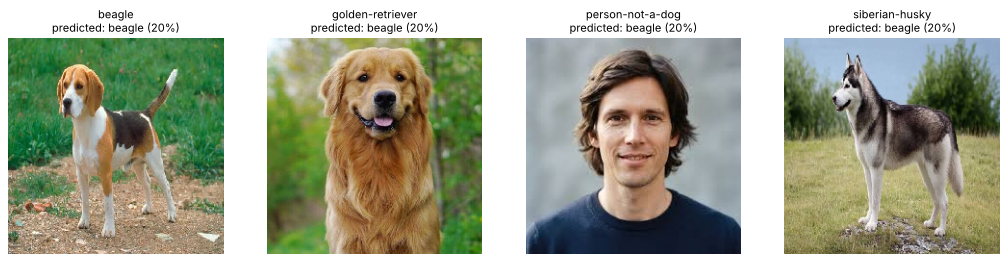

beagle.jpeg              -> beagle (20%)
golden-retriever.jpeg    -> beagle (20%)
person-not-a-dog.jpeg    -> beagle (20%)
siberian-husky.jpeg      -> beagle (20%)


In [47]:
import tensorflow as tf

custom_paths = sorted((DATA / "dog-photos").glob("*.jpeg"))     # beagle, golden-retriever, person-not-a-dog, ...
custom_images = np.stack([tf.keras.utils.img_to_array(tf.keras.utils.load_img(p, target_size=IMG_SIZE))
                          for p in custom_paths])                 # (n, 224, 224, 3), values 0-255
custom_preds = loaded_model.predict(custom_images, verbose=0)

fig, axes = plt.subplots(1, len(custom_paths), figsize=(4 * len(custom_paths), 4.3))
for ax, path, img, probs in zip(np.atleast_1d(axes), custom_paths, custom_images, custom_preds):
    ax.imshow(img.astype("uint8")); ax.axis("off")
    ax.set_title(f"{path.stem}\npredicted: {get_pred_label(probs)} ({probs.max():.0%})", fontsize=10)
plt.show()
for path, probs in zip(custom_paths, custom_preds):
    print(f"{path.name:24s} -> {get_pred_label(probs)} ({probs.max():.0%})")

#### Exercise 15

Add **data augmentation** (random horizontal flips, small rotations and zoom) that applies only during training. Put an
augmentation block in front of the base model, rebuild, and train for the same number of epochs.

#### Solution 15

*Try it yourself before running this cell.*

In [48]:
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")                 # active in fit(), automatically disabled in predict()/evaluate()

base = create_model().layers[1]              # reuse the same (frozen) feature extractor
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = base(x, training=False)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
aug_model = tf.keras.Model(inputs, outputs)
aug_model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
aug_history = aug_model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, verbose=2)

ImageNet weights unavailable ( Exception ) - using untrained weights for a dry run.


Epoch 1/2


5/5 - 15s - 3s/step - accuracy: 0.2313 - loss: 1.6017 - val_accuracy: 0.1250 - val_loss: 1.5976


Epoch 2/2


5/5 - 4s - 784ms/step - accuracy: 0.2500 - loss: 1.5884 - val_accuracy: 0.1250 - val_loss: 1.5887


<a id="cheatsheet-tensorflow-and-keras"></a>

### Cheatsheet: TensorFlow and Keras

```python
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(path, label_mode="categorical",
    image_size=(224, 224), batch_size=32, validation_split=0.2, subset="both", seed=42)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
base = tf.keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet", pooling="avg")
base.trainable = False
inputs = tf.keras.Input((224, 224, 3)); x = base(inputs, training=False)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x); model = tf.keras.Model(inputs, outputs)
model.compile(loss="categorical_crossentropy", optimizer=tf.keras.optimizers.Adam(1e-3), metrics=["accuracy"])
model.fit(train_ds, validation_data=valid_ds, epochs=10,
          callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
model.predict(ds).argmax(axis=1); model.save("model.keras"); tf.keras.models.load_model("model.keras")
```

| Labels | Loss |
|---|---|
| one-hot (`label_mode="categorical"`) | `CategoricalCrossentropy` |
| integers (`label_mode="int"`) | `SparseCategoricalCrossentropy` |
| binary (single sigmoid output) | `BinaryCrossentropy` |

<a id="reference"></a>

## Reference

Everything from the whole post in one place.

<a id="master-cheatsheet"></a>

### Master Cheatsheet

**The workflow:** problem → data → metric → features → model (train / validation / test) → experiment, then repeat.

```python
# pandas
df = pd.read_csv(path, parse_dates=["date"], low_memory=False)
df.info(); df.describe(); df.isna().sum(); df["col"].value_counts(); pd.crosstab(df.a, df.b)
df["col"] = df["col"].fillna(df["col"].median()); df = df.dropna(subset=["target"])
monthly = df.set_index("date")["value"].resample("MS").sum()          # "ME", "QE", "YE" for period ends
# NumPy
rng = np.random.default_rng(42); a.shape; a.reshape(-1, 1); a @ b; a.mean(axis=0); a.argmax(axis=1)
# Matplotlib
fig, ax = plt.subplots(figsize=(10, 6)); ax.scatter(x, y, c=labels); ax.set(title="...", xlabel="...")
# scikit-learn
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
pipe = Pipeline([("prep", ColumnTransformer([...])), ("model", RandomForestClassifier())]).fit(X_train, y_train)
cross_val_score(pipe, X, y, cv=5, scoring="f1"); classification_report(y_test, pipe.predict(X_test))
RandomizedSearchCV(pipe, {"model__n_estimators": [100, 200]}, n_iter=10, cv=5); dump(pipe, "model.joblib")
# Text
text_clf = make_pipeline(CountVectorizer(analyzer=clean_text), MultinomialNB())     # or TfidfVectorizer, ComplementNB
# Recommender
matrix = ratings.pivot_table(index="user_id", columns="title", values="rating"); matrix.corr(min_periods=80)
# Prophet
m = Prophet(yearly_seasonality=5).fit(df[["ds", "y"]]); fc = m.predict(m.make_future_dataframe(24, freq="MS"))
# Keras
model = keras.Sequential([keras.Input((32, 32, 3)), layers.Conv2D(32, 3, activation="relu"),
                          layers.MaxPooling2D((2, 2)), layers.Flatten(), layers.Dense(10, activation="softmax")])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(X, y, validation_split=0.1, callbacks=[keras.callbacks.EarlyStopping(restore_best_weights=True)])
np.argmax(model.predict(X), axis=1); model.save("m.keras"); keras.models.load_model("m.keras")
base = keras.applications.EfficientNetV2B0(include_top=False, pooling="avg"); base.trainable = False
```

| Problem | Start with | Metric |
|---|---|---|
| Tabular classification | logistic regression, random forest, gradient boosting | accuracy, precision / recall / F1, ROC AUC |
| Tabular regression | linear model first, then random forest, `HistGradientBoostingRegressor` | MAE, RMSE, R², RMSLE |
| Time-ordered data | the same, plus date features and a time-based split | as above |
| Forecasting one series | Prophet, against a last-value baseline | MAPE, MAE on a holdout period |
| Short text | bag of words + Naive Bayes | precision / recall per class, balanced accuracy |
| Recommendations | item-item correlation with a minimum overlap | hit rate on held-out ratings |
| Small images | a small CNN with dropout and augmentation | accuracy, confusion matrix |
| Photos, text, audio | transfer learning with a pretrained network | accuracy, top-k accuracy |

<a id="old-api-to-current-api"></a>

### Old API to Current API

| Old code | Current replacement |
|---|---|
| `load_boston()` | `fetch_california_housing()` |
| `plot_roc_curve`, `plot_confusion_matrix` | `RocCurveDisplay`, `ConfusionMatrixDisplay` |
| `max_features="auto"` | `"sqrt"` or `1.0` |
| `mean_squared_log_error(..., squared=False)` | `root_mean_squared_log_error` |
| `vectorizer.get_feature_names()` | `vectorizer.get_feature_names_out()` |
| `df.append(other)`, `series.append(other)` | `pd.concat([df, other])` |
| `pd.read_csv(..., error_bad_lines=False)` | `pd.read_csv(..., on_bad_lines="skip")` |
| `resample("Y")`, `("M")`, `("Q")` | `resample("YE")`, `("ME")`, `("QE")` |
| `plt.style.use("seaborn")` | `plt.style.use("seaborn-v0_8")` |
| `sns.countplot(df["col"])` | `sns.countplot(x=df["col"])` |
| `from fbprophet import Prophet` | `from prophet import Prophet` |
| `Dense(25, input_dim=5)` | `keras.Input(shape=(5,))` then `Dense(25)` |
| `model.predict_classes(X)` | `np.argmax(model.predict(X), axis=1)` |
| `model.fit_generator(gen, ...)` | `model.fit(dataset_or_arrays, ...)` |
| `ImageDataGenerator(...)` | `layers.RandomFlip`, `layers.RandomRotation`, … inside the model |
| `Adam(lr=0.001)`, `nb_epoch=50` | `Adam(learning_rate=0.001)`, `epochs=50` |
| `history.history["acc"]` | `history.history["accuracy"]` |
| `scipy.misc.toimage(x)` | `plt.imshow(x)` or `keras.utils.array_to_img(x)` |
| `hub.KerasLayer(...)`, `.h5` files | `keras.applications`, `.keras` files |

<a id="glossary"></a>

### Glossary

| Term | Meaning |
|---|---|
| **Accuracy** | share of predictions that are correct |
| **Activation function** | non-linear function applied to a neuron's weighted sum (ReLU, sigmoid, softmax) |
| **Augmentation** | random label-preserving changes to training images to improve generalisation |
| **AUC / ROC curve** | area under / plot of true-positive vs false-positive rate across thresholds |
| **Backpropagation** | chain-rule computation of the loss gradient for every weight |
| **Bag of words** | document represented by word counts, ignoring order |
| **Batch** | group of samples processed together in one training step |
| **Bayes' theorem** | posterior = likelihood × prior / marginal likelihood |
| **Callback** | function Keras runs during training (early stopping, logging) |
| **Changepoint** | date where Prophet allows the trend's slope to change |
| **Classification / regression** | predicting a category / a number |
| **Collaborative filtering** | recommending from the ratings matrix alone, via similar users or items |
| **Confusion matrix** | table of true classes (rows) against predicted classes (columns) |
| **Convolution** | sliding a small kernel over an image to produce a feature map |
| **Cross-validation** | evaluating on several train/test splits and averaging |
| **Dropout** | randomly disabling neurons during training to reduce overfitting |
| **Epoch** | one full pass over the training data |
| **Estimator** | scikit-learn's word for a model |
| **Feature / target** | input variable / what you predict |
| **Feature engineering** | creating new features from existing data |
| **Feature map** | output of one convolution filter: where its pattern appears |
| **Gradient descent** | adjusting parameters step by step in the direction that reduces the loss |
| **Hyperparameter** | a setting you choose before training |
| **Imputation** | filling missing values |
| **Learning rate** | size of each gradient descent step |
| **MAPE** | mean absolute percentage error |
| **One-hot encoding** | one 0/1 column per category |
| **Overfitting / underfitting** | memorizing the training data / failing to learn its patterns |
| **Pipeline** | preprocessing steps and a model fitted as one object |
| **Pooling** | downsampling a feature map by taking the max or mean of small blocks |
| **Precision / recall / F1** | correctness of positive predictions / coverage of actual positives / their harmonic mean |
| **Prior / likelihood / posterior** | class probability before the data / probability of the data given a class / class probability after it |
| **R², MAE, RMSE, RMSLE** | variance explained, mean absolute error, root mean squared (log) error |
| **Seasonality** | a pattern that repeats on a fixed cycle (yearly, weekly) |
| **Softmax** | turns outputs into probabilities that sum to 1 |
| **Stop words** | very common words removed before counting |
| **Tensor** | multi-dimensional array that can run on a GPU |
| **TF-IDF** | term frequency weighted by how rare the term is across documents |
| **Train / validation / test set** | data to learn from / to tune on / for the final evaluation |
| **Transfer learning** | reusing a model trained on one problem for another |

<a id="further-reading"></a>

### Further Reading

- [Data Preparation for Machine Learning reference](https://github.com/rokon-uddin/data-preparation-reference), my
  deep dive on cleaning, feature selection, transforms, pipelines and leakage
- [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html) ·
  [NumPy user guide](https://numpy.org/doc/stable/user/index.html) ·
  [Matplotlib quick start](https://matplotlib.org/stable/users/explain/quick_start.html)
- [scikit-learn user guide](https://scikit-learn.org/stable/user_guide.html) ·
  [choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html) ·
  [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html) ·
  [working with text data](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) ·
  [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)
- [Prophet documentation](https://facebook.github.io/prophet/) and the paper *Forecasting at Scale* (Taylor and
  Letham, 2017)
- [Keras developer guides](https://keras.io/guides/) · [Keras applications](https://keras.io/api/applications/) ·
  [TensorFlow transfer-learning tutorial](https://www.tensorflow.org/tutorials/images/transfer_learning)
- [Gradient-based learning applied to document recognition](http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf),
  the LeNet paper
- Datasets: [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease) ·
  [Blue Book for Bulldozers](https://www.kaggle.com/c/bluebook-for-bulldozers) ·
  [Chicago Data Portal](https://data.cityofchicago.org/) ·
  [MovieLens](https://grouplens.org/datasets/movielens/) ·
  [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) ·
  [GTSRB](https://benchmark.ini.rub.de/gtsrb_news.html) ·
  [Stanford Dogs](http://vision.stanford.edu/aditya86/ImageNetDogs/)